# Reaching self-consistency: mixing, Kerker, and unstable solutions

Self-consistency is a fixed point, and a root of the residual is the same statement:

$$\rho = F[\rho]
\qquad\Longleftrightarrow\qquad
r[\rho] \equiv F[\rho] - \rho = 0$$

Every notebook before this one reached it by iterating $F$ and damping the iteration. This
one is about what makes that hard and what a different route buys.

**Charge sloshing, and the preconditioner that removes it.** A metal screens: its dielectric
function diverges as $q^{-2}$ at long wavelength, so a small charge imbalance at the scale of
the cell is amplified by the Hartree term from one iteration to the next. Dividing that
divergence out is Kerker preconditioning,

$$\beta \;\longrightarrow\; \beta\,
   \frac{|\mathbf G|^2}{|\mathbf G|^2 + q_{\rm TF}^2},$$

On an aluminium slab, half metal and half vacuum, it takes the iteration count from
**24 to 15**. This is when the Anderson fit treats every wavelength alike. There is a second
cure for the same divergence. If the fit measures the residual by its Hartree energy, as
`pw.x` does, the long wavelengths count the most and the fit removes them first. Then plain
Anderson takes **13** with no preconditioner at all. **With more vacuum Kerker loses**,
because it screens the vacuum as well: 14 to 35 iterations, against 13 to 15 for Anderson.
Screening from the local density of states at the Fermi level takes **11 iterations at 16
and at 64 bohr** of vacuum.

**Solving $r[\rho] = 0$ as a root instead.** It is not faster, and it does something no mixer
can: it converges on **unstable** self-consistent solutions. Iron's non-magnetic state is a
fixed point of the same equations that damped mixing always slides off, and it is the
reference a magnetic stabilisation energy is quoted against.

In [1]:
from pathlib import Path
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from defuqumat import Calculator
from defuqumat.scf import Calculation, run_scf

PSEUDO = Path("../tests/data/pseudo")

# The benchmark inputs carry their own conv_thr and electron_maxstep, which
# `from_file` reads, so this helper is the path and nothing else.
def load(name):
    return Calculator.from_file(Path("../benchmarks") / name,
                                pseudo_dir=PSEUDO, announce=False)

aluminium = load("al-slab.in")
slab, slab_pseudos = aluminium.system, aluminium.pseudos
print(f"Al(100), {len(slab.structure.positions)} layers, "
      f"c = {slab.cell.at[2, 2]:.1f} bohr, {slab.kpoints.coords.shape[0]} k-points")

Al(100), 5 layers, c = 31.0 bohr, 3 k-points


## The problem: half the cell screens, half does not

A slab has metal in one half of the cell and vacuum, which screens nothing at all, in the
other. Long-wavelength charge transfer between the two is amplified by exactly the
$q^{-2}$ the metal's screening produces, and the result is charge sloshing back and forth
across the cell, visible in the first few iterations of a plain run.

In [2]:
# The Anderson fit, measured with every wavelength alike, and with the Hartree energy
# of the residual (pw.x's measure, and the default).
sloshing = aluminium.get_scf(mixing_fit="flat")
anderson = aluminium.get_scf()
for label, run in (("every wavelength alike", sloshing), ("Hartree energy", anderson)):
    energies = [h["total_energy"] for h in run.history]
    print(f"{label:24s} {run.iterations:3d} iterations, "
          f"worst total energy along the way {max(energies):+8.2f} Ry")
print(f"the converged total energy is {anderson.total_energy:.8f} Ry")

every wavelength alike    24 iterations, worst total energy along the way  +105.53 Ry
Hartree energy            13 iterations, worst total energy along the way  +105.53 Ry
the converged total energy is -20.87908225 Ry


## Two cures for one divergence

Anderson mixing builds the next density from the past ones. It takes the combination that
makes the residual smallest. But smallest in which measure? Both runs above reach the same
+105 Ry, because that happens on the second step, before the fit has a history. What
differs is how fast the sloshing is removed after that. If every wavelength counts the same,
the long-wavelength charge transfer across the cell survives the fit, and the Hartree term
amplifies it again at every step.

The first cure is Kerker preconditioning. `mixing_mode = 'kerker'` damps the long-wavelength
components of the step by the Thomas-Fermi factor. This is an approximate inverse of the
dielectric response that causes the sloshing.

The second cure is the measure itself. The Hartree energy of the residual is

$$\|R\|^2 = \sum_{\mathbf G} \frac{4\pi e^2}{|\mathbf G|^2}\,|R(\mathbf G)|^2 .$$

Here the long wavelengths have the largest weight, so the fit removes them first. This is
the quantity `conv_thr` measures. It is also the measure `pw.x` uses, and the default here.

Two things about Kerker are physical, not adjustable. The screening wavevector comes from
the electron density of the cell, $r_s = (3\Omega/4\pi N)^{1/3}$ and
$q_{\rm TF}^2 = (12/\pi)^{2/3}/r_s$. So it is a property of the material. A hand-picked
value over-screens this slab. Also only the **charge** channel is screened. The
magnetization has no $q^{-2}$ divergence, because spin density is not screened by the
Hartree term.

In [3]:
from defuqumat.scf.mixing import thomas_fermi_screening

nelec = aluminium.calculation.nelec
q_tf = thomas_fermi_screening(float(slab.cell.volume), nelec) ** 0.5
print(f"q_TF from the cell = {q_tf:.3f} 1/bohr   (a hand-picked 1.5 over-screens by "
      f"{(1.5/q_tf)**2:.1f}x in q^2)")

kerker = aluminium.get_scf(mixing_mode="kerker")
print(f"Anderson, every wavelength alike  {sloshing.iterations:3d} iterations")
print(f"Anderson + Kerker                 {kerker.iterations:3d} iterations   "
      f"(same answer to {abs(kerker.total_energy - anderson.total_energy):.1e} Ry)")
print(f"Anderson, Hartree energy          {anderson.iterations:3d} iterations")

q_TF from the cell = 1.008 1/bohr   (a hand-picked 1.5 over-screens by 2.2x in q^2)


Anderson, every wavelength alike   24 iterations
Anderson + Kerker                  14 iterations   (same answer to 5.3e-08 Ry)
Anderson, Hartree energy           13 iterations


## When the vacuum grows: screening from the states at the Fermi level

Kerker treats the whole cell as one metal. In a slab the longest wavelength along the
normal, $2\pi/c$, lives mostly in the vacuum, where nothing screens and the dielectric
eigenvalue is 1, so damping it by $|\mathbf G|^2/(|\mathbf G|^2 + q_{\rm TF}^2)$ only slows
the iteration, and by more the longer the cell. The win above turns into a loss once the
vacuum is long enough.

The cure is to screen only where there are states to screen with. With $D(\mathbf r)$ the
local density of states at the Fermi level, the response of a system that screens through
those states alone is

$$\tilde\chi_0\,\delta V = -D\,\delta V + D\,\frac{\int D\,\delta V}{\int D},
\qquad
\rho_{\rm in} \;\longrightarrow\; \rho_{\rm in} + \beta\,(1 - \tilde\chi_0 v_H)^{-1} R .$$

A uniform $D$ gives back Kerker with $q_{\rm TF}^2 = 8\pi D$; where $D$ vanishes, in the
vacuum or across a whole insulator, nothing is screened, and the step is the plain one.
This is `mixing_mode = 'ldos'` (Herbst and Levitt), and $D$ costs almost nothing to know:
it is the density's own sum over bands with $\delta(\varepsilon_F - \varepsilon_{n\mathbf k})$
in place of the occupation.

vacuum 16 bohr:  anderson  13   kerker  14   ldos  11


vacuum 64 bohr:  anderson  15   kerker  35   ldos  11
in the middle of the vacuum: density 1.1e-06, LDOS 1.5e-06 of their maxima


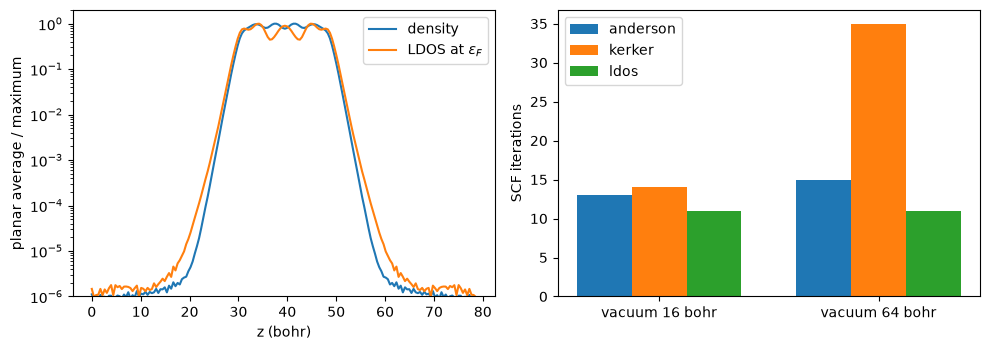

In [4]:
far = load("al-slab-v64.in")
counts = {}
for label, calc in (("16 bohr", aluminium), ("64 bohr", far)):
    counts[label] = {mode: calc.get_scf(mixing_mode=mode).iterations
                     for mode in ("anderson", "kerker", "ldos")}
    print(f"vacuum {label}:  " + "   ".join(f"{m} {n:3d}" for m, n in counts[label].items()))

# The LDOS at the Fermi level on the 64-bohr slab, from its converged states: the
# density's own pass with delta(e_F - e) in place of the occupations.
scf = far.get_scf(mixing_mode="ldos")
calculation = far.calculation
levels = {"smearing": 0.0, "fermi_energy": scf.fermi_energy}
_, rho, ldos = calculation.density_and_ldos(
    scf.wavefunctions, np.asarray(scf.occupations)[None],
    calculation.ldos_weights(scf.eigenvalues_by_spin, levels))
grid = calculation.basis.dense.grid
c = float(far.system.cell.at[2, 2])
z = np.arange(grid[2]) * c / grid[2]
density_z = np.asarray(rho)[0].mean(axis=(0, 1))
ldos_z = np.asarray(ldos).reshape(grid).mean(axis=(0, 1))
print(f"in the middle of the vacuum: density {density_z[0] / density_z.max():.1e}, "
      f"LDOS {ldos_z[0] / ldos_z.max():.1e} of their maxima")

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.semilogy(z, density_z / density_z.max(), label="density")
left.semilogy(z, ldos_z / ldos_z.max(), label="LDOS at $\\varepsilon_F$")
left.set_xlabel("z (bohr)")
left.set_ylabel("planar average / maximum")
left.set_ylim(1e-6, 2)
left.legend()
modes = ("anderson", "kerker", "ldos")
width = 0.25
for i, mode in enumerate(modes):
    right.bar(np.arange(2) + (i - 1) * width, [counts[l][mode] for l in counts],
              width, label=mode)
right.set_xticks(np.arange(2), [f"vacuum {l}" for l in counts])
right.set_ylabel("SCF iterations")
right.legend()
fig.tight_layout()
plt.show()

Kerker's count grows from 14 to 35 as the vacuum goes from 16 to 64 bohr. Plain Anderson in the Hartree measure stays at 13 to 15, and the LDOS preconditioner takes 11 at both. The left panel shows why. The states at the Fermi level fill the metal. They fall by six orders of magnitude to the middle of the vacuum, as the density does. So the operator screens the slab like a metal and leaves the vacuum alone, while Kerker screens both. The same reasoning says that a monolayer, which has no thickness to slosh across, needs no screening at all. We measured plain Anderson to be flat in the vacuum there. On an insulator $D$ is zero, and the mode is exactly plain Anderson.

## The opposite failure: a run that crawls

Kerker answers an SCF that is **oscillating**: the charge sloshes, the Hartree term amplifies
it from one iteration to the next, and the cure is to damp the long wavelengths. The opposite
failure is an SCF whose residual is small and never turns around, and a magnet is where that
one lives.

Without spin-orbit coupling, rotating every moment in the cell together costs no energy at
all. The self-consistency residual therefore has **no component along that rotation**: the
fixed point is a whole family rather than a point, and the iteration has to cross that
direction rather than descend it. Twisting the moments slowly instead of rigidly costs only
the spin-wave energy $D q^2$, which vanishes as the cell gets longer. Damping harder does
nothing for a direction like that. The step has to get *longer*.

`mixing_mode = 'adaptive'` is Elk's scheme and does exactly that. It carries one step length
per component of the density and moves it by the sign of that component's residual: up while
the residual keeps pushing the same way, halved when it turns over. A component the iteration
is crawling along accelerates on its own, and one that overshoots is cut back, so it is a
stall detector with nothing to tune.

One thing to know before reaching for it. `mixing_beta` means something different here: it is
the **increment** by which each step length grows, and the floor it falls back to, rather than
a step length itself. It is small on purpose, and leaving it unset gives every mixing mode its
own default.


In [5]:
# bcc iron with its moment in the plane: ultrasoft, PBE, and noncollinear, so the
# soft direction above is available to it. The input carries its own conv_thr and
# mixing_beta, which `from_file` reads.
IRON = Path("../tests/data/qe/fe-noncolin-pbe-stress.in")

magnetic = {}
for mode in ("anderson", "adaptive"):
    run = Calculator.from_file(IRON, pseudo_dir=PSEUDO, announce=False)
    magnetic[mode] = run.get_scf(mixing_mode=mode)
    steps = sum(h["davidson_iterations"] for h in magnetic[mode].history)
    print(f"{mode:9s} {magnetic[mode].iterations:3d} iterations, "
          f"{steps:3.0f} Davidson steps   E = {magnetic[mode].total_energy:.9f} Ry")

gap = abs(magnetic["adaptive"].total_energy - magnetic["anderson"].total_energy)
moments = [np.asarray(magnetic[m].magnetization_vector) for m in magnetic]
print(f"\nthe same fixed point: energies {gap:.1e} Ry apart, "
      f"moments {np.abs(moments[0] - moments[1]).max():.1e} mu_B apart")


anderson   16 iterations,  34 Davidson steps   E = -55.788729937 Ry


adaptive   16 iterations,  42 Davidson steps   E = -55.788729937 Ry

the same fixed point: energies 1.1e-10 Ry apart, moments 7.6e-05 mu_B apart


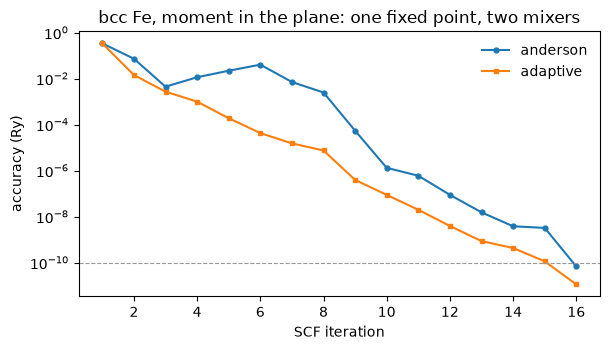

In [6]:
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for mode, style in (("anderson", "-o"), ("adaptive", "-s")):
    accuracy = [h["accuracy"] for h in magnetic[mode].history]
    ax.semilogy(range(1, len(accuracy) + 1), accuracy, style, ms=3.5, label=mode)
ax.axhline(1e-10, color="0.6", lw=0.8, ls="--")
ax.set_xlabel("SCF iteration")
ax.set_ylabel("accuracy (Ry)")
ax.set_title("bcc Fe, moment in the plane: one fixed point, two mixers")
ax.legend(frameon=False)
fig.tight_layout()


The iteration count is the bigger number and the Davidson count is the honest one. Fewer
iterations means the density error falls faster, and the diagonalisation threshold is
scheduled from that error, so the eigensolver is held tighter sooner and each iteration
costs more: the step counts above close most of the gap between the two ratios. The saving
is real, and it is the smaller of the two figures.


## The same fixed point, as a root to be found

`scf_solver = 'newton-krylov'` solves $r[\rho] = 0$ instead of iterating $F$. The Jacobian
is never formed, which on even this smallest case would be a $10368 \times 10368$ matrix;
the Krylov solver asks only for its action on a vector.

The figure compares all three on the quantity `conv_thr` measures, the Hartree energy of the
density residual. **The x axis is diagonalisations, not iterations**, which is the only
currency in which a mixer's step and a Krylov step are comparable.

all three agree to 5.3e-08 Ry


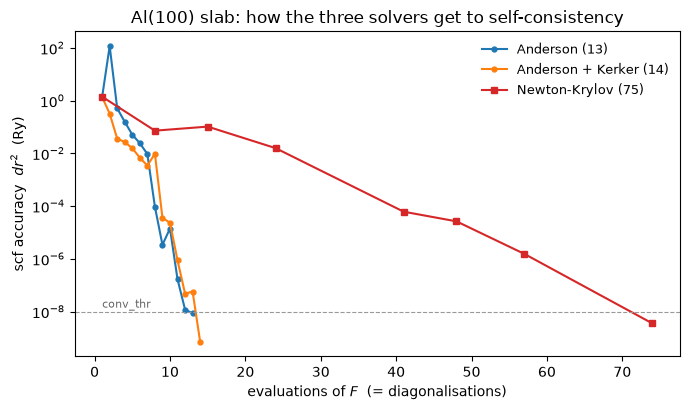

In [7]:
newton = aluminium.get_scf(scf_solver="newton-krylov",
                           scf_solver_options={"forcing": 0.5})

fig, ax = plt.subplots(figsize=(7.0, 4.2))
for label, result, colour in [("Anderson", anderson, "tab:blue"),
                              ("Anderson + Kerker", kerker, "tab:orange")]:
    accuracy = [h["accuracy"] for h in result.history]
    ax.semilogy(np.arange(1, len(accuracy) + 1), accuracy, "o-", ms=3.5,
                color=colour, label=f"{label} ({result.iterations})")
outer = newton.solver.history
ax.semilogy([h["steps"] for h in outer], [h["accuracy"] for h in outer], "s-", ms=4.5,
            color="tab:red", label=f"Newton-Krylov ({newton.solver.steps + newton.iterations})")
ax.axhline(1e-8, color="0.6", lw=0.8, ls="--")
ax.text(1, 1.4e-8, "conv_thr", color="0.4", fontsize=8)
ax.set_xlabel("evaluations of $F$  (= diagonalisations)")
ax.set_ylabel(r"scf accuracy  $dr^2$  (Ry)")
ax.set_title("Al(100) slab: how the three solvers get to self-consistency")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

print(f"all three agree to "
      f"{max(abs(r.total_energy - anderson.total_energy) for r in (kerker, newton)):.1e} Ry")

The outer iteration count of the root-finder is small, but each outer step is paid for
in inner ones. We measured a sweep of the vacuum thickness. The numbers are quoted here, not
run, and all are evaluations of $F$:

| vacuum (bohr) | Anderson | Anderson + Kerker | `ldos` | Newton-Krylov |
|---|---|---|---|---|
| 16 | 13 | 14 | **11** | 75 |
| 32 | 15 | 20 | **11** | 149 |
| 48 | 18 | 27 | **11** | 138 |
| 64 | 15 | 35 | **11** | 200 |

On cost the answer is mixing. Plain Anderson is enough for a short vacuum, `ldos` for a long
one, and mixing stays the default.

## What a Jacobian is worth: an unstable solution

Iron has two self-consistent solutions at this geometry. The ferromagnetic one is the ground
state; the non-magnetic one is a fixed point of the same equations that damped mixing never
reaches, because mixing is a relaxation and from any magnetic starting point it runs downhill
into the stable solution. A root-finder is stability-blind: it converges on whichever root it
started nearest to. That is how the non-magnetic reference energy of a magnet is obtained
without constraining anything.

Which root is nearest must be arranged, not hoped for. So we kick the state away from the
symmetric solution, and we give the *same* kicked state to both solvers. The kick has the
shape of the atomic magnetization, and its size is 0.12 (0.06 added to one spin channel and
taken from the other). This also measures the size of the basin. Below a kick of 0.10,
mixing comes back to the non-magnetic state. From 0.10 up, mixing runs away to the
ferromagnet. The root-finder comes back from 0.10 to 0.14, and not at 0.15. So the
non-magnetic solution of iron is metastable, not a sharp saddle.

In [8]:
ferrum = load("fe-unstable.in")
iron, iron_pseudos = ferrum.system, ferrum.pseudos
options = dict(conv_thr=1e-8, max_iterations=200)

# The symmetric root: nothing in the SCF breaks spin symmetry on its own.
calculation = ferrum.calculation
rho = np.asarray(calculation.starting_density())
symmetric = jnp.asarray(np.repeat(rho.mean(axis=0, keepdims=True), rho.shape[0], axis=0))
root = run_scf(iron, iron_pseudos, calculation=Calculation(iron, iron_pseudos), **options,
               starting_density=symmetric)

# Kick it out of its basin, in the direction the instability lives in, and hand the
# *same* perturbed state to both solvers.
shape = rho[0] - rho[1]
shape = shape / np.abs(shape).max()
base = np.asarray(root.density)
kicked = jnp.asarray(np.stack([base[0] + 0.06 * shape, base[1] - 0.06 * shape]))

mixed = run_scf(iron, iron_pseudos, calculation=Calculation(iron, iron_pseudos), **options,
                starting_density=kicked)
saddle = run_scf(iron, iron_pseudos, calculation=Calculation(iron, iron_pseudos), **options,
                 starting_density=kicked, scf_solver="newton-krylov",
                 scf_solver_options={"forcing": 0.1, "gmres_maxiter": 20,
                                     "max_iterations": 30, "kerker": True})

# The check is free and shares nothing with either run above.
reference = load("fe-unstable-nonmagnetic.in").get_scf()

print(f"{'from the same kicked symmetric root':<40} {'E (Ry)':>15} {'m (mu_B)':>10}")
print(f"{'  Anderson, nspin = 2':<40} {mixed.total_energy:15.8f} "
      f"{float(mixed.magnetization):10.4f}")
print(f"{'  Newton-Krylov, nspin = 2':<40} {saddle.total_energy:15.8f} "
      f"{float(saddle.magnetization):10.4f}")
print(f"{'  nspin = 1 (independent reference)':<40} {reference.total_energy:15.8f} "
      f"{'--':>10}")
print(f"\nNewton's root matches the nspin = 1 reference to "
      f"{abs(saddle.total_energy - reference.total_energy):.1e} Ry")
print(f"iron's magnetic stabilisation energy = "
      f"{1000 * (saddle.total_energy - mixed.total_energy):.1f} mRy")

from the same kicked symmetric root               E (Ry)   m (mu_B)
  Anderson, nspin = 2                       -55.44642602     3.4052
  Newton-Krylov, nspin = 2                  -55.38228995     0.0001
  nspin = 1 (independent reference)         -55.38228995         --

Newton's root matches the nspin = 1 reference to 9.3e-10 Ry
iron's magnetic stabilisation energy = 64.1 mRy


With a looser inner solve (`forcing = 0.5` and at most 8 GMRES steps), the same solver
starts from the same kicked state. It also converges, and it reports an accuracy below
`conv_thr`. But it lands on the *ferromagnetic* solution. A rough inner solve makes the
Newton step close to a damped mixing step, and a mixing step flows to the stable root.
Switching the Kerker preconditioner off does not change which root each inner solve finds.
So on a problem with more than one solution, the accuracy of the inner solve decides which
physics comes out. Both answers look equally converged.

## The same thing with DFT+U

The occupation matrix of the Hubbard shell is a variable of the SCF in its own right, mixed
alongside the density, so a root-finder solves for it on the same footing.

DFT+U has an unstable solution of its own, and reaching it takes more than an unpolarised
density: the occupation matrix is filled by Hund's rule at the start, so the majority and
minority $d$ orbitals begin unequal whatever the starting magnetization is, and a polarised
occupation matrix regenerates the Hubbard potential that undoes a kick to the density alone.
Starting from a uniform occupation matrix instead is what puts the run near the symmetric
solution.

The test is the definition of an unstable fixed point: perturb it, and see which solver
comes back.

In [9]:
from defuqumat.hubbard import uniform_ns

nickel_calc = load("ni-u-unstable.in")
nickel, nickel_pseudos = nickel_calc.system, nickel_calc.pseudos
setup = nickel_calc.calculation
print("init_ns eigenvalues per spin (Hund's rule):",
      *[np.round(np.linalg.eigvalsh(np.asarray(setup.starting_ns())[s, 0]), 2)
        for s in range(2)])

# The saddle: a spin-symmetric density and an orbitally uniform ns.
rho = np.asarray(setup.starting_density())
start = dict(starting_density=jnp.asarray(np.repeat(rho.mean(0, keepdims=True), 2, axis=0)),
             starting_becsum=setup.starting_becsum(),
             starting_ns=uniform_ns(setup.hubbard, setup.nspin))
saddle = run_scf(nickel, nickel_pseudos, calculation=Calculation(nickel, nickel_pseudos),
                 conv_thr=1e-9, max_iterations=150, **start)
print(f"the saddle:  E = {saddle.total_energy:.8f} Ry   m = {float(saddle.magnetization):+.6f}")

# Kick it 2% along the magnetization direction, in both rho and ns.
scale = np.array([1.02, 0.98])[:, None, None, None]
kicked = dict(starting_density=jnp.asarray(np.asarray(saddle.density) * scale),
              starting_becsum=setup.starting_becsum(),
              starting_ns=jnp.asarray(np.asarray(saddle.ns) * scale))

away = run_scf(nickel, nickel_pseudos, calculation=Calculation(nickel, nickel_pseudos),
               conv_thr=1e-9, max_iterations=150, **kicked)
back = run_scf(nickel, nickel_pseudos, calculation=Calculation(nickel, nickel_pseudos),
               conv_thr=1e-9, max_iterations=150, scf_solver="newton-krylov",
               scf_solver_options={"forcing": 0.1, "gmres_maxiter": 30, "max_iterations": 15},
               **kicked)
print(f"{'from the perturbed saddle':<28} {'E (Ry)':>15} {'m (mu_B)':>11}")
print(f"{'  Anderson (runs away)':<28} {away.total_energy:15.8f} {float(away.magnetization):11.6f}")
print(f"{'  Newton-Krylov (returns)':<28} {back.total_energy:15.8f} {float(back.magnetization):11.6f}")


init_ns eigenvalues per spin (Hund's rule): [1. 1. 1. 1. 1.] [0.8 0.8 0.8 0.8 0.8]


the saddle:  E = -86.20620046 Ry   m = +0.000000


from the perturbed saddle             E (Ry)    m (mu_B)
  Anderson (runs away)          -86.41841670    2.000000
  Newton-Krylov (returns)       -86.20620046    0.000003


Mixing amplifies the kick into the ferromagnet, which is what makes the state unstable, and
the root-finder puts it back.

One caveat. Started *far* from the symmetric solution, which root the search finds depends
on the inner-solve accuracy in no systematic way: three settings gave the ferromagnet, a
third solution at $m = -0.34$, and the ferromagnet again, all converged and all reporting an
accuracy below `conv_thr`. On a problem with several solutions it is the starting state that
selects one, not the solver's tuning.

---
The tests behind this notebook: `tests/regression/test_scf_solvers.py`,
`tests/unit/test_fermi_response.py`.